# AML 02 — Building Classification

**Objective.** Classify `BUILDINGID` from Wi-Fi signal-strength features using the canonical preprocessing pipeline, feature definitions, and shared train, internal-validation, and held-out-validation split.

**Inputs (read-only, produced by `ML_01_data_preparation_features.ipynb`):**
- `data/processed/aml_internal_train_features.csv` — fit model configurations here.
- `data/processed/aml_internal_validation_features.csv` — select model configurations here.
- `data/processed/aml_heldout_validation_features.csv` — final, single-use evaluation only.

**Held-out isolation.** This notebook does not open, inspect, or test the existence of the
held-out file until *after* the model configuration is frozen (Section 6, "Freeze model
configuration"). Every cell before that point touches only the internal-training and
internal-validation tables. Section 6 marks the freeze point explicitly; the held-out file
path is defined early (as a `Path`, never dereferenced) purely so the later load does not
need to invent a new variable.

This notebook is self-contained: it does not depend on any variable from another notebook
or an interactive session.

**Project:** Project 9 — Indoor Location Prediction Using Wi-Fi Signals  
**Phase:** AML (Phase 1)  
**Pipeline:** Building Classification

## Notebook navigation

- [1. Environment and configuration](#---)
- [2. Data schema, feature allowlist, and split validation](#----w---)
- [3. Model family and configuration rationale](#-----)
- [4. Baseline model](#--)
- [5. Hyperparameter tuning](#--)
- [6. Freeze model configuration](#---)
- [7. Final held-out evaluation](#----)
- [8. Building confusion matrix (held-out validation)](#------)
- [9. Exported outputs and downstream use](#----w-)
- [10. Summary, comparison, observations, assumptions, and limitations](#------)
- [Conclusion](#)
- [Next Steps](#-)


## 1. Environment and configuration

Imports, reproducibility settings, and repository-relative paths are initialized in the code cells below. This notebook is designed to run independently from a fresh kernel.


**Cell purpose:** Imports the required packages and reports the active Python environment.


In [1]:
from pathlib import Path
import platform
import re
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print(f"Python: {platform.python_version()} ({sys.executable})")
print(f"NumPy: {np.__version__}; pandas: {pd.__version__}; scikit-learn: {sklearn.__version__}; "
      f"matplotlib: {plt.matplotlib.__version__}; seaborn: {sns.__version__}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


Python: 3.14.2 (/Users/Krishiv/Desktop/Signal2Space/.venv/bin/python)
NumPy: 2.5.4; pandas: 3.0.6; scikit-learn: 1.9.1; matplotlib: 3.11.2; seaborn: 0.13.2


**Cell purpose:** Locates the repository and defines the canonical input and output directories.


In [2]:
def find_project_root(start=None):
    candidate = Path.cwd() if start is None else Path(start)
    for parent in (candidate, *candidate.parents):
        if (parent / "data/processed/aml_internal_train_features.csv").is_file() and (parent / "Machine Learning Pipeline").is_dir():
            return parent
    raise FileNotFoundError("Could not locate repository root from the current working directory")

PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "data" / "tables"
FIGURES_DIR = PROJECT_ROOT / "data" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_PATH = PROCESSED_DIR / "aml_internal_train_features.csv"
INTERNAL_VAL_PATH = PROCESSED_DIR / "aml_internal_validation_features.csv"
# Held-out path is only DEFINED here, per the isolation protocol above. It is not checked
# for existence (.is_file()) or opened until the "Final held-out evaluation" section below,
# which runs strictly after the model configuration is frozen.
HELDOUT_PATH = PROCESSED_DIR / "aml_heldout_validation_features.csv"

assert TRAIN_PATH.is_file(), f"Expected canonical preprocessing output not found: {TRAIN_PATH}"
assert INTERNAL_VAL_PATH.is_file(), f"Expected canonical preprocessing output not found: {INTERNAL_VAL_PATH}"
print("Repository root:", PROJECT_ROOT)
print("Internal-training input:", TRAIN_PATH.relative_to(PROJECT_ROOT))
print("Internal-validation input:", INTERNAL_VAL_PATH.relative_to(PROJECT_ROOT))
print("Held-out input path (not yet read):", HELDOUT_PATH.relative_to(PROJECT_ROOT))

# Output paths for downstream floor-classification and integration artifacts. Defining these here
# does not touch the held-out file either.
INTERNAL_VAL_PREDICTIONS_PATH = TABLES_DIR / "ml_02_building_internal_validation_predictions.csv"
HELDOUT_PREDICTIONS_PATH = TABLES_DIR / "ml_02_building_heldout_predictions.csv"
METRICS_PATH = TABLES_DIR / "ml_02_building_metrics.csv"
HELDOUT_CONFUSION_PATH = TABLES_DIR / "ml_02_building_heldout_confusion_matrix.csv"


Repository root: /Users/Krishiv/Desktop/Signal2Space
Internal-training input: data/processed/aml_internal_train_features.csv
Internal-validation input: data/processed/aml_internal_validation_features.csv
Held-out input path (not yet read): data/processed/aml_heldout_validation_features.csv


**Cell purpose:** Loads canonical development feature tables.


In [3]:
internal_train = pd.read_csv(TRAIN_PATH)
internal_validation = pd.read_csv(INTERNAL_VAL_PATH)

print("internal_train:", internal_train.shape)
print("internal_validation:", internal_validation.shape)
print("Source partitions:", internal_train.SOURCE_PARTITION.unique(), internal_validation.SOURCE_PARTITION.unique())

internal_train: (16085, 1057)
internal_validation: (3852, 1057)
Source partitions: <StringArray>
['trainingData']
Length: 1, dtype: str <StringArray>
['trainingData']
Length: 1, dtype: str


## 2. Data schema, feature allowlist, and split validation

canonical `FEATURE_COLUMNS` allowlist (`RSSI_Z__WAPnnn` scaled signal, `SEEN__WAPnnn`
observed-signal indicator, and six per-row summaries) is reconstructed here from the actual
column names in the internal-training and internal-validation tables — not assumed — and
checked for consistency. Target columns (`BUILDINGID`, `FLOOR`, `LONGITUDE`, `LATITUDE`) and
identifier/metadata columns (`ROW_ID`, `SOURCE_PARTITION`, `SPACEID`, `RELATIVEPOSITION`,
`USERID`, `PHONEID`, `TIMESTAMP`) are excluded from the predictor matrix but retained for row
alignment and error analysis. Group separation `(BUILDINGID, FLOOR, SPACEID)` between the two
splits is also verified directly from these two tables, independent of notebook execution state.

**Cell purpose:** Reconstructs the feature allowlist and validates target and identifier exclusions.


In [4]:
TARGET_COLUMNS = ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
IDENTIFIER_COLUMNS = ["ROW_ID", "SOURCE_PARTITION", "SPACEID", "RELATIVEPOSITION", "USERID", "PHONEID", "TIMESTAMP"]
BUILDING_TARGET = "BUILDINGID"
GROUP_COLUMNS = ["BUILDINGID", "FLOOR", "SPACEID"]

rssi_cols = sorted(
    [c for c in internal_train.columns if re.fullmatch(r"RSSI_Z__WAP\d+", c)],
    key=lambda c: int(re.search(r"\d+", c).group()),
)
seen_cols = sorted(
    [c for c in internal_train.columns if re.fullmatch(r"SEEN__WAP\d+", c)],
    key=lambda c: int(re.search(r"\d+", c).group()),
)
summary_cols = ["n_heard", "max_rssi_dbm", "mean_rssi_dbm", "std_rssi_dbm", "n_strong", "top1_ap_index"]
FEATURE_COLUMNS = rssi_cols + seen_cols + summary_cols

assert len(rssi_cols) == len(seen_cols) == 520, "Expected 520 WAP columns for each of RSSI_Z__ and SEEN__"
assert all(c in internal_train.columns for c in summary_cols), "Missing expected per-row summary columns"
assert not (set(FEATURE_COLUMNS) & set(TARGET_COLUMNS) | set(FEATURE_COLUMNS) & set(IDENTIFIER_COLUMNS)), \
    "Predictor allowlist leaks a target or identifier column"

for name, frame in [("internal_train", internal_train), ("internal_validation", internal_validation)]:
    missing = [c for c in FEATURE_COLUMNS + TARGET_COLUMNS + IDENTIFIER_COLUMNS if c not in frame.columns]
    assert not missing, f"{name} is missing expected columns: {missing}"

assert internal_train[FEATURE_COLUMNS].columns.tolist() == internal_validation[FEATURE_COLUMNS].columns.tolist(), \
    "Feature column order differs between internal_train and internal_validation"

print("Predictor feature count:", len(FEATURE_COLUMNS), "(", len(rssi_cols), "scaled RSSI +", len(seen_cols), "seen indicators +", len(summary_cols), "summaries )")
print("Excluded from predictors (targets):", TARGET_COLUMNS)
print("Excluded from predictors (identifiers, retained separately):", IDENTIFIER_COLUMNS)

Predictor feature count: 1046 ( 520 scaled RSSI + 520 seen indicators + 6 summaries )
Excluded from predictors (targets): ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']
Excluded from predictors (identifiers, retained separately): ['ROW_ID', 'SOURCE_PARTITION', 'SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']


**Cell purpose:** Checks feature validity, labels, row IDs, and group separation.


In [5]:
# Finite/missing-value checks, row-identifier uniqueness, and valid building classes
# -- internal splits only.
for name, frame in [("internal_train", internal_train), ("internal_validation", internal_validation)]:
    feature_matrix = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float64)
    assert np.isfinite(feature_matrix).all(), f"{name} has non-finite predictor values"
    assert frame[BUILDING_TARGET].notna().all(), f"{name} has missing {BUILDING_TARGET} labels"
    assert frame["ROW_ID"].is_unique, f"{name} has duplicate ROW_ID values"

# Group separation: (BUILDINGID, FLOOR, SPACEID) groups must not be shared between the two
# internal splits, verified directly from the processed tables (not merely trusted from
# canonical preprocessing documentation).
train_group_keys = set(
    internal_train[GROUP_COLUMNS].astype(str).agg("_".join, axis=1)
)
internal_val_group_keys = set(
    internal_validation[GROUP_COLUMNS].astype(str).agg("_".join, axis=1)
)
assert train_group_keys.isdisjoint(internal_val_group_keys), \
    "internal_train and internal_validation share at least one (BUILDINGID, FLOOR, SPACEID) group"
assert set(internal_train.ROW_ID).isdisjoint(set(internal_validation.ROW_ID)), \
    "internal_train and internal_validation share at least one ROW_ID"
print(f"Verified disjoint (BUILDINGID, FLOOR, SPACEID) groups: {len(train_group_keys)} train groups, "
      f"{len(internal_val_group_keys)} validation groups, 0 shared.")
print("Verified disjoint ROW_ID sets between internal_train and internal_validation.")

train_building_classes = set(internal_train[BUILDING_TARGET].unique())
internal_val_building_classes = set(internal_validation[BUILDING_TARGET].unique())
BUILDING_CLASSES = sorted(train_building_classes)
print("Building classes observed in internal_train:", sorted(train_building_classes))
print("Building classes observed in internal_validation:", sorted(internal_val_building_classes))
absent_from_internal_val = train_building_classes - internal_val_building_classes
extra_in_internal_val = internal_val_building_classes - train_building_classes
if absent_from_internal_val:
    print(f"Note: building class(es) {sorted(absent_from_internal_val)} present in internal_train but absent from internal_validation.")
assert not extra_in_internal_val, f"internal_validation contains building class(es) {sorted(extra_in_internal_val)} never seen in internal_train"
print("Confusion-matrix / class label set (fixed to internal-training classes):", BUILDING_CLASSES)

Verified disjoint (BUILDINGID, FLOOR, SPACEID) groups: 588 train groups, 147 validation groups, 0 shared.
Verified disjoint ROW_ID sets between internal_train and internal_validation.
Building classes observed in internal_train: [np.int64(0), np.int64(1), np.int64(2)]
Building classes observed in internal_validation: [np.int64(0), np.int64(1), np.int64(2)]
Confusion-matrix / class label set (fixed to internal-training classes): [np.int64(0), np.int64(1), np.int64(2)]


## 3. Model family and configuration rationale

**Random Forest** (`sklearn.ensemble.RandomForestClassifier`) is selected. This is a choice
of fit for the task, not a claim that it outperforms XGBoost — XGBoost is not benchmarked
here, so no comparative performance claim is made.

- The predictor matrix is wide (1,046 columns: 520 scaled-RSSI + 520 observed-signal
  indicators + 6 summaries) and highly sparse/discrete (most WAPs are unobserved at any one
  location). Bagged decision-tree ensembles handle this natively, without needing further
  feature scaling or missing-value-imputation assumptions beyond what shared preprocessing notebook already
  applied.
- Random Forest's hyperparameter surface (tree count, depth, leaf size) is compact enough
  for the small, reproducible grid search in Section 5.


## 4. Baseline model

A default-hyperparameter Random Forest is fit on the internal-training split and scored on
internal validation. This anchors the comparison against the tuned configuration in
Section 9.

**Cell purpose:** Creates predictor matrices and building-class targets.


In [6]:
X_train = internal_train[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y_train = internal_train[BUILDING_TARGET].to_numpy()

X_internal_val = internal_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y_internal_val = internal_validation[BUILDING_TARGET].to_numpy()

print("X_train:", X_train.shape, "| X_internal_val:", X_internal_val.shape)

X_train: (16085, 1046) | X_internal_val: (3852, 1046)


**Cell purpose:** Fits and scores the baseline random forest.


In [7]:
baseline_model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
baseline_model.fit(X_train, y_train)
baseline_fit_seconds = time.time() - t0

baseline_pred = baseline_model.predict(X_internal_val)
baseline_accuracy = accuracy_score(y_internal_val, baseline_pred)
baseline_macro_f1 = f1_score(y_internal_val, baseline_pred, average="macro")
print(f"Baseline fit time: {baseline_fit_seconds:.2f}s")
print(f"Baseline internal-validation accuracy: {baseline_accuracy:.4f} | macro F1: {baseline_macro_f1:.4f}")

Baseline fit time: 0.50s
Baseline internal-validation accuracy: 0.9995 | macro F1: 0.9995


## 5. Hyperparameter tuning

Tuning uses **only** the internal-training split (to fit) and the internal-validation split
(to score) — the held-out file has not been opened anywhere above this point. Each grid
point is a Random Forest fit once on `X_train`/`y_train` and scored once on
`X_internal_val`/`y_internal_val`: a real, executed search over a small, computationally
manageable 18-point grid, not a cross-validated search, matching the fixed internal
train/validation contract established by the shared grouped split. The random seed is fixed for
reproducibility. Selection criterion is internal-validation accuracy, with macro F1 as a
tie-breaker.

**Cell purpose:** Trains and compares candidate configurations on internal validation.


In [8]:
PARAM_GRID = [
    {"n_estimators": n_estimators, "max_depth": max_depth, "min_samples_leaf": min_samples_leaf}
    for n_estimators in (100, 200, 300)
    for max_depth in (None, 20, 30)
    for min_samples_leaf in (1, 2)
]
print("Grid points to evaluate:", len(PARAM_GRID))

tuning_results = []
for params in PARAM_GRID:
    t0 = time.time()
    model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
    model.fit(X_train, y_train)
    fit_seconds = time.time() - t0
    pred = model.predict(X_internal_val)
    tuning_results.append({
        **params,
        "internal_val_accuracy": accuracy_score(y_internal_val, pred),
        "internal_val_macro_f1": f1_score(y_internal_val, pred, average="macro"),
        "fit_seconds": fit_seconds,
    })

tuning_results_df = pd.DataFrame(tuning_results).sort_values(
    ["internal_val_accuracy", "internal_val_macro_f1"], ascending=False
).reset_index(drop=True)
tuning_results_df

Grid points to evaluate: 18


,n_estimators,max_depth,min_samples_leaf,internal_val_accuracy,internal_val_macro_f1,fit_seconds
0,100,NaN,1,0.999481,0.999497,0.753467
1,200,NaN,1,0.999481,0.999497,1.019007
2,300,NaN,1,0.999481,0.999497,1.246302
3,100,NaN,2,0.999221,0.999247,0.515562
4,100,20.0,1,0.999221,0.999247,0.375257
5,100,20.0,2,0.999221,0.999247,0.413343
6,100,30.0,1,0.999221,0.999247,0.393595
7,100,30.0,2,0.999221,0.999247,0.527748
8,200,NaN,2,0.999221,0.999247,1.301001
9,200,20.0,1,0.999221,0.999247,0.919883


## 6. Freeze model configuration

The configuration is selected **now**, from internal-validation results only. Nothing below
this cell revises features, model family, hyperparameters, or thresholds based on held-out
performance — the held-out file is not even loaded until Section 7, strictly after this
freeze.

**Cell purpose:** Selects and freezes the configuration using internal validation.


In [9]:
best_row = tuning_results_df.iloc[0]
BEST_PARAMS = {
    "n_estimators": int(best_row["n_estimators"]),
    "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    "min_samples_leaf": int(best_row["min_samples_leaf"]),
}
print("Selected configuration (by internal-validation accuracy, macro F1 tie-break):", BEST_PARAMS)
print(f"Selected internal-validation accuracy: {best_row['internal_val_accuracy']:.4f} | macro F1: {best_row['internal_val_macro_f1']:.4f}")

# Fit the frozen configuration on internal training only. This model object is reused,
# unmodified, for both the internal-validation export below and the held-out evaluation in
# Section 7 -- it is never refit or adjusted after this point.
final_model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **BEST_PARAMS)
final_model.fit(X_train, y_train)
print("Configuration frozen and final_model fit on internal_train only.")
print("Held-out file has not been opened by any cell up to and including this one.")

Selected configuration (by internal-validation accuracy, macro F1 tie-break): {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}
Selected internal-validation accuracy: 0.9995 | macro F1: 0.9995


Configuration frozen and final_model fit on internal_train only.
Held-out file has not been opened by any cell up to and including this one.


## 7. Final held-out evaluation

The held-out file is opened for the first time in this notebook **here**, strictly after the
configuration freeze in Section 6. Its schema is validated the same way the internal splits
were, then the already-frozen `final_model` (fit only on internal training) scores it once.

**How to interpret these scores.** The supplied partition and grouped development split do not guarantee that every Wi-Fi fingerprint is unique across training and evaluation data; repeated two-dimensional coordinate values may also occur. Scores therefore describe performance under the current split and do not establish generalization to unseen fingerprints or unseen positions. The current research question uses the supplied split; adopt a stricter fingerprint- or position-grouped split only if that research question changes.

**Cell purpose:** Loads held-out rows after model freeze and computes final predictions.


In [10]:
# First access to the held-out file anywhere in this notebook.
assert HELDOUT_PATH.is_file(), f"Expected canonical preprocessing output not found: {HELDOUT_PATH}"
heldout_validation = pd.read_csv(HELDOUT_PATH)
print("heldout_validation:", heldout_validation.shape)

missing = [c for c in FEATURE_COLUMNS + TARGET_COLUMNS + IDENTIFIER_COLUMNS if c not in heldout_validation.columns]
assert not missing, f"heldout_validation is missing expected columns: {missing}"
assert heldout_validation[FEATURE_COLUMNS].columns.tolist() == internal_train[FEATURE_COLUMNS].columns.tolist(), \
    "Feature column order in heldout_validation differs from internal_train"
assert heldout_validation.SOURCE_PARTITION.eq("validationData").all(), \
    "heldout_validation does not carry the expected 'validationData' source partition"
heldout_feature_matrix = heldout_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float64)
assert np.isfinite(heldout_feature_matrix).all(), "heldout_validation has non-finite predictor values"
assert heldout_validation[BUILDING_TARGET].notna().all(), "heldout_validation has missing BUILDINGID labels"
assert heldout_validation["ROW_ID"].is_unique, "heldout_validation has duplicate ROW_ID values"
print("heldout_validation schema validated; SOURCE_PARTITION:", heldout_validation.SOURCE_PARTITION.unique())

X_heldout = heldout_validation[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
y_heldout = heldout_validation[BUILDING_TARGET].to_numpy()

heldout_pred = final_model.predict(X_heldout)
heldout_proba = final_model.predict_proba(X_heldout)
assert set(np.unique(heldout_pred)).issubset(set(BUILDING_CLASSES)), \
    "Model predicted a building class absent from internal training"

heldout_accuracy = accuracy_score(y_heldout, heldout_pred)
heldout_macro_f1 = f1_score(y_heldout, heldout_pred, average="macro")
print(f"Held-out validation building accuracy: {heldout_accuracy:.4f}")
print(f"Held-out validation building macro F1: {heldout_macro_f1:.4f}")
print("No feature, hyperparameter, or model-family decision above this point was revised using this result.")

heldout_validation: (1111, 1057)
heldout_validation schema validated; SOURCE_PARTITION: <StringArray>
['validationData']
Length: 1, dtype: str
Held-out validation building accuracy: 0.9973
Held-out validation building macro F1: 0.9971
No feature, hyperparameter, or model-family decision above this point was revised using this result.


## 8. Building confusion matrix (held-out validation)

Rows are true `BUILDINGID`, columns are predicted `BUILDINGID`. Labels are fixed to
`BUILDING_CLASSES` (the classes observed in internal training), so a class absent from a
split still appears as an all-zero row/column rather than disappearing. If a held-out class
has no examples, its row-normalized values are defined as zeros.


**Cell purpose:** Computes held-out confusion counts and per-class rates.


In [11]:
heldout_confusion_counts = confusion_matrix(y_heldout, heldout_pred, labels=BUILDING_CLASSES)
heldout_confusion_counts_df = pd.DataFrame(
    heldout_confusion_counts,
    index=[f"true_{c}" for c in BUILDING_CLASSES],
    columns=[f"pred_{c}" for c in BUILDING_CLASSES],
)
heldout_confusion_counts_df

,pred_0,pred_1,pred_2
true_0,535,1,0
true_1,1,305,1
true_2,0,0,268


**Cell purpose:** Normalizes the confusion matrix by actual building class.


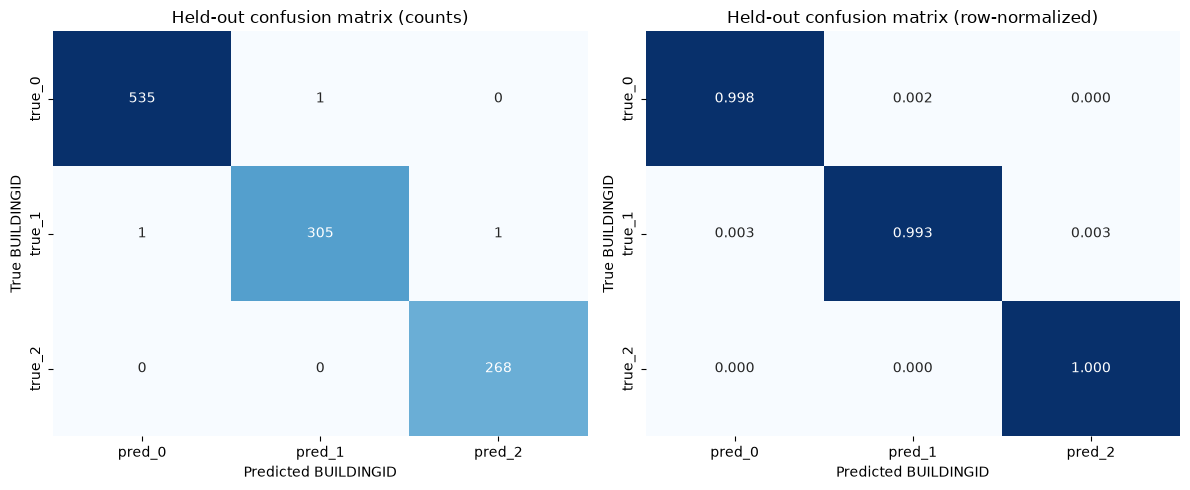

In [12]:
row_totals = heldout_confusion_counts.sum(axis=1, keepdims=True)
heldout_confusion_normalized = np.divide(
    heldout_confusion_counts.astype(np.float64),
    row_totals,
    out=np.zeros_like(heldout_confusion_counts, dtype=np.float64),
    where=row_totals != 0,
)
heldout_confusion_normalized_df = pd.DataFrame(
    heldout_confusion_normalized,
    index=[f"true_{c}" for c in BUILDING_CLASSES],
    columns=[f"pred_{c}" for c in BUILDING_CLASSES],
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(heldout_confusion_counts_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Held-out confusion matrix (counts)", xlabel="Predicted BUILDINGID", ylabel="True BUILDINGID")
sns.heatmap(heldout_confusion_normalized_df, annot=True, fmt=".3f", cmap="Blues", cbar=False, vmin=0, vmax=1, ax=axes[1])
axes[1].set(title="Held-out confusion matrix (row-normalized)", xlabel="Predicted BUILDINGID", ylabel="True BUILDINGID")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ml_02_building_heldout_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()


## 9. Exported outputs and downstream use

Four CSVs are written to the existing `data/processed/` directory for floor-classification and integration notebooks
to join by `(SOURCE_PARTITION, ROW_ID)`. No predictors or unrelated columns are included, and
no existing file (canonical preprocessing inputs, or any other) is overwritten.

| File | Columns | Rows |
|---|---|---|
| `ml_02_building_internal_validation_predictions.csv` | `ROW_ID`, `SOURCE_PARTITION`, `BUILDINGID_TRUE`, `BUILDINGID_PRED`, `PROBA_BUILDING_0/1/2` | one per internal-validation row |
| `ml_02_building_heldout_predictions.csv` | same columns | one per held-out row |
| `ml_02_building_metrics.csv` | `split`, `model_config`, `n_estimators`, `max_depth`, `min_samples_leaf`, `accuracy`, `macro_f1`, `n_rows` | one per reported evaluation (baseline internal-validation, tuned internal-validation, tuned held-out) |
| `ml_02_building_heldout_confusion_matrix.csv` | `true_building`, `pred_building`, `count`, `proportion_of_true_row` | one per (true, predicted) class pair |

Probability columns are included because `RandomForestClassifier.predict_proba` computes
them; they are named `PROBA_BUILDING_{class}` for each class in `BUILDING_CLASSES`.

**Cell purpose:** Defines row-aligned prediction tables with class probabilities.


In [13]:
def predictions_frame(frame, predictions, probabilities, probability_classes):
    out = pd.DataFrame({
        "ROW_ID": frame["ROW_ID"].to_numpy(),
        "SOURCE_PARTITION": frame["SOURCE_PARTITION"].to_numpy(),
        "BUILDINGID_TRUE": frame[BUILDING_TARGET].to_numpy(),
        "BUILDINGID_PRED": predictions,
    })
    for cls in BUILDING_CLASSES:
        col = f"PROBA_BUILDING_{cls}"
        out[col] = (
            probabilities[:, probability_classes.index(cls)]
            if cls in probability_classes else 0.0
        )
    return out

# Reuse the held-out predictions and probabilities already computed for final evaluation.
# The held-out model is not called a second time during export.
internal_val_pred_for_export = final_model.predict(X_internal_val)
internal_val_proba_for_export = final_model.predict_proba(X_internal_val)
model_classes = list(final_model.classes_)
internal_val_predictions = predictions_frame(
    internal_validation, internal_val_pred_for_export,
    internal_val_proba_for_export, model_classes
)
heldout_predictions = predictions_frame(
    heldout_validation, heldout_pred, heldout_proba, model_classes
)

assert len(internal_val_predictions) == len(internal_validation)
assert len(heldout_predictions) == len(heldout_validation)
assert internal_val_predictions["ROW_ID"].is_unique and heldout_predictions["ROW_ID"].is_unique

internal_val_predictions.to_csv(INTERNAL_VAL_PREDICTIONS_PATH, index=False)
heldout_predictions.to_csv(HELDOUT_PREDICTIONS_PATH, index=False)
print("Wrote", INTERNAL_VAL_PREDICTIONS_PATH.relative_to(PROJECT_ROOT), "rows:", len(internal_val_predictions))
print("Wrote", HELDOUT_PREDICTIONS_PATH.relative_to(PROJECT_ROOT), "rows:", len(heldout_predictions))


Wrote data/tables/ml_02_building_internal_validation_predictions.csv rows: 3852
Wrote data/tables/ml_02_building_heldout_predictions.csv rows: 1111


**Cell purpose:** Creates and exports baseline, tuned, and held-out building metrics.


In [14]:
metrics_rows = [
    {
        "split": "internal_validation", "model_config": "baseline",
        "n_estimators": baseline_model.n_estimators, "max_depth": baseline_model.max_depth,
        "min_samples_leaf": baseline_model.min_samples_leaf,
        "accuracy": baseline_accuracy, "macro_f1": baseline_macro_f1, "n_rows": len(internal_validation),
    },
    {
        "split": "internal_validation", "model_config": "tuned",
        "n_estimators": BEST_PARAMS["n_estimators"], "max_depth": BEST_PARAMS["max_depth"],
        "min_samples_leaf": BEST_PARAMS["min_samples_leaf"],
        "accuracy": float(best_row["internal_val_accuracy"]), "macro_f1": float(best_row["internal_val_macro_f1"]),
        "n_rows": len(internal_validation),
    },
    {
        "split": "heldout_validation", "model_config": "tuned",
        "n_estimators": BEST_PARAMS["n_estimators"], "max_depth": BEST_PARAMS["max_depth"],
        "min_samples_leaf": BEST_PARAMS["min_samples_leaf"],
        "accuracy": heldout_accuracy, "macro_f1": heldout_macro_f1, "n_rows": len(heldout_validation),
    },
]
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(METRICS_PATH, index=False)
print("Wrote", METRICS_PATH.relative_to(PROJECT_ROOT))
metrics_df

Wrote data/tables/ml_02_building_metrics.csv


,split,model_config,n_estimators,max_depth,min_samples_leaf,accuracy,macro_f1,n_rows
0,internal_validation,baseline,100,None,1,0.999481,0.999497,3852
1,internal_validation,tuned,100,None,1,0.999481,0.999497,3852
2,heldout_validation,tuned,100,None,1,0.997300,0.997126,1111


**Cell purpose:** Exports the held-out confusion matrix in long-form CSV.


In [15]:
confusion_long_rows = []
for i, true_cls in enumerate(BUILDING_CLASSES):
    row_total = heldout_confusion_counts[i].sum()
    for j, pred_cls in enumerate(BUILDING_CLASSES):
        count = int(heldout_confusion_counts[i, j])
        confusion_long_rows.append({
            "true_building": true_cls,
            "pred_building": pred_cls,
            "count": count,
            "proportion_of_true_row": (count / row_total) if row_total else 0.0,
        })
confusion_long_df = pd.DataFrame(confusion_long_rows)
confusion_long_df.to_csv(HELDOUT_CONFUSION_PATH, index=False)
print("Wrote", HELDOUT_CONFUSION_PATH.relative_to(PROJECT_ROOT))
confusion_long_df

Wrote data/tables/ml_02_building_heldout_confusion_matrix.csv


,true_building,pred_building,count,proportion_of_true_row
0,0,0,535,0.998134
1,0,1,1,0.001866
2,0,2,0,0.000000
3,1,0,1,0.003257
4,1,1,305,0.993485
5,1,2,1,0.003257
6,2,0,0,0.000000
7,2,1,0,0.000000
8,2,2,268,1.000000


**Cell purpose:** Reloads prediction and metric tables to verify schema, labels, alignment, and values.


In [16]:
# Round-trip verification: exact schema, row alignment, labels, probabilities, metrics,
# and confusion counts must match the values computed in this run.
reloaded_internal_val = pd.read_csv(INTERNAL_VAL_PREDICTIONS_PATH)
reloaded_heldout = pd.read_csv(HELDOUT_PREDICTIONS_PATH)
reloaded_metrics = pd.read_csv(METRICS_PATH)
reloaded_confusion = pd.read_csv(HELDOUT_CONFUSION_PATH)

expected_prediction_columns = [
    "ROW_ID", "SOURCE_PARTITION", "BUILDINGID_TRUE", "BUILDINGID_PRED",
    *[f"PROBA_BUILDING_{cls}" for cls in BUILDING_CLASSES],
]
assert reloaded_internal_val.columns.tolist() == expected_prediction_columns
assert reloaded_heldout.columns.tolist() == expected_prediction_columns
assert len(reloaded_internal_val) == len(internal_validation)
assert len(reloaded_heldout) == len(heldout_validation)
assert reloaded_internal_val["ROW_ID"].tolist() == internal_validation["ROW_ID"].tolist()
assert reloaded_heldout["ROW_ID"].tolist() == heldout_validation["ROW_ID"].tolist()
assert reloaded_internal_val["SOURCE_PARTITION"].eq("trainingData").all()
assert reloaded_heldout["SOURCE_PARTITION"].eq("validationData").all()
assert np.array_equal(reloaded_internal_val["BUILDINGID_TRUE"], internal_validation[BUILDING_TARGET])
assert np.array_equal(reloaded_heldout["BUILDINGID_TRUE"], heldout_validation[BUILDING_TARGET])
assert np.array_equal(reloaded_internal_val["BUILDINGID_PRED"], internal_val_pred_for_export)
assert np.array_equal(reloaded_heldout["BUILDINGID_PRED"], heldout_pred)
probability_columns = [c for c in expected_prediction_columns if c.startswith("PROBA_BUILDING_")]
assert np.allclose(reloaded_internal_val[probability_columns], internal_val_proba_for_export)
assert np.allclose(reloaded_heldout[probability_columns], heldout_proba)

assert reloaded_metrics.columns.tolist() == metrics_df.columns.tolist()
assert reloaded_metrics["split"].tolist() == metrics_df["split"].tolist()
assert np.allclose(reloaded_metrics[["accuracy", "macro_f1"]], metrics_df[["accuracy", "macro_f1"]])
assert reloaded_metrics["n_rows"].tolist() == metrics_df["n_rows"].tolist()

expected_confusion = confusion_long_df.sort_values(
    ["true_building", "pred_building"]
).reset_index(drop=True)
reloaded_confusion = reloaded_confusion.sort_values(
    ["true_building", "pred_building"]
).reset_index(drop=True)
pd.testing.assert_frame_equal(reloaded_confusion, expected_confusion, check_dtype=False)
assert reloaded_confusion["count"].sum() == len(heldout_validation)
print("All four exports round-trip verified: schemas, row alignment, labels, probabilities, metrics, and confusion counts match this run.")


All four exports round-trip verified: schemas, row alignment, labels, probabilities, metrics, and confusion counts match this run.


## 10. Summary, comparison, observations, assumptions, and limitations

The cell below computes every number in this summary from the current run; nothing here is
hard-coded.

**Cell purpose:** Displays a baseline-versus-tuned internal-validation comparison.


In [17]:
comparison_df = pd.DataFrame([
    {"model_config": "baseline", **{k: getattr(baseline_model, k) for k in ("n_estimators", "max_depth", "min_samples_leaf")},
     "internal_val_accuracy": baseline_accuracy, "internal_val_macro_f1": baseline_macro_f1},
    {"model_config": "tuned", **BEST_PARAMS,
     "internal_val_accuracy": float(best_row["internal_val_accuracy"]), "internal_val_macro_f1": float(best_row["internal_val_macro_f1"])},
])
comparison_df["accuracy_delta_vs_baseline"] = comparison_df["internal_val_accuracy"] - baseline_accuracy
display(comparison_df)


,model_config,n_estimators,max_depth,min_samples_leaf,internal_val_accuracy,internal_val_macro_f1,accuracy_delta_vs_baseline
0,baseline,100,None,1,0.999481,0.999497,0.0
1,tuned,100,None,1,0.999481,0.999497,0.0


## Conclusion

This notebook trains and tunes the building classifier using the canonical feature allowlist and shared split. The comparison table and exported metrics retain baseline, tuned, and held-out results. Interpret the held-out score under the supplied split, including possible fingerprint overlap and repeated coordinate values.

## Next Steps

Use the row-level building predictions and metrics in the integrated AML evaluation. Interpret building accuracy alongside floor accuracy, coordinate error, and the hierarchical building-floor breakdown.